# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [5]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [6]:
clean_aviation_data=pd.read_csv('AviationData_Cleaned_Master.csv')
clean_aviation_data.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,...,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Year,Total.Onboard,Injury.Rate,Is.Destroyed
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,Incident,Minor,Airplane,9VSQQ,...,0.0,588.0,Vmc,Taxi,Probable Cause,04-12-2014,1983.0,588.0,0.0,0.0
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,Fatal(1),Destroyed,Airplane,N9600W,...,0.0,0.0,Imc,Cruise,Probable Cause,02-05-2011,1983.0,2.0,1.0,1.0
2,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,Incident,Minor,Airplane,N898AA,...,0.0,100.0,Vmc,Taxi,Probable Cause,11-06-2018,1983.0,100.0,0.0,0.0
3,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,Non-Fatal,Substantial,Airplane,N1882D,...,0.0,1.0,Vmc,Climb,Probable Cause,05-05-2011,1983.0,1.0,0.0,0.0
4,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,Non-Fatal,Substantial,Airplane,N2697K,...,0.0,1.0,Vmc,Takeoff,Probable Cause,01-02-2016,1983.0,1.0,0.0,0.0


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [13]:
clean_aviation_data['Unique.Aircraft.Type'] = clean_aviation_data['Make'] + " " + clean_aviation_data['Model']
model_capacities = clean_aviation_data.groupby('Unique.Aircraft.Type')['Total.Onboard'].max()
clean_aviation_data['Max.Model.Capacity'] = clean_aviation_data['Unique.Aircraft.Type'].map(model_capacities)
small_aircraft_df = clean_aviation_data[(clean_aviation_data['Number.of.Engines'] <= 2) & (clean_aviation_data['Max.Model.Capacity'] <= 10)].copy()
large_aircraft_df = clean_aviation_data[(clean_aviation_data['Number.of.Engines'] >= 2) & (clean_aviation_data['Max.Model.Capacity'] > 10)].copy()
print({small_aircraft_df.shape})
print({large_aircraft_df.shape})

{(15549, 33)}
{(835, 33)}


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

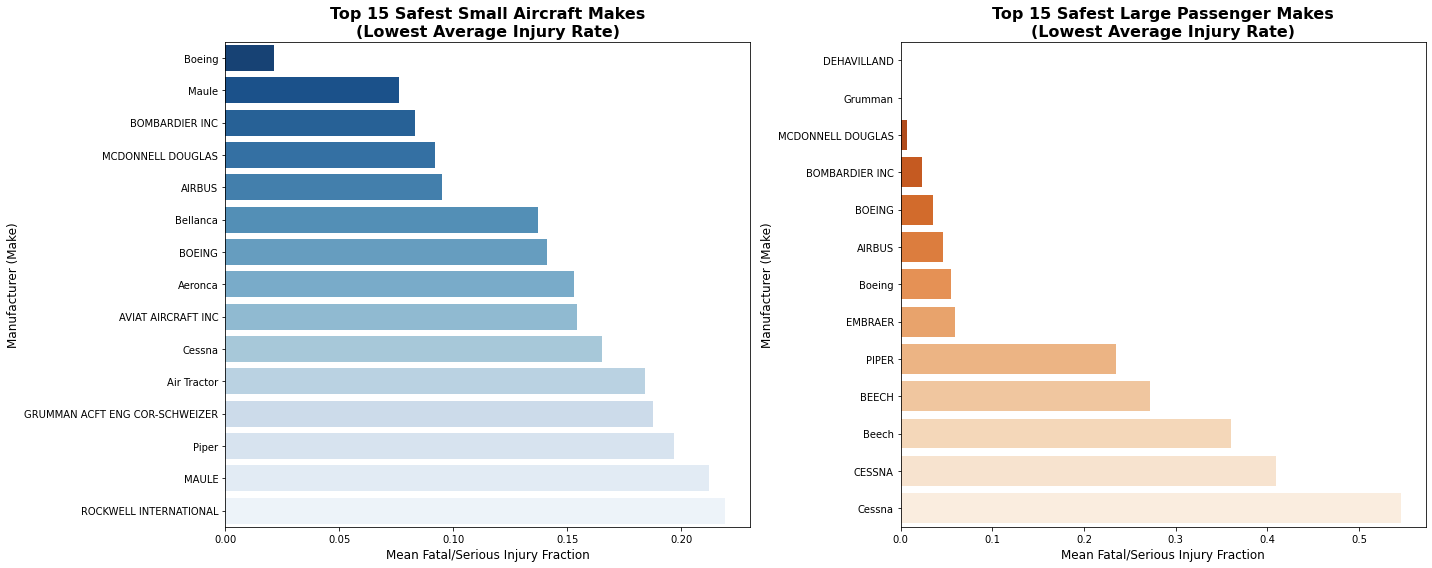

In [21]:
small_makes_safety = small_aircraft_df.groupby('Make')['Injury.Rate'].mean().reset_index()
top_15_small_makes = small_makes_safety.sort_values(by='Injury.Rate').head(15)
large_makes_safety = large_aircraft_df.groupby('Make')['Injury.Rate'].mean().reset_index()
top_15_large_makes = large_makes_safety.sort_values(by='Injury.Rate').head(15)
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharex=False)

sns.barplot(
    data=top_15_small_makes, 
    y='Make', 
    x='Injury.Rate', 
    ax=axes[0], 
    palette='Blues_r'
)

sns.barplot(data=top_15_large_makes, y='Make', x='Injury.Rate', ax=axes[1], palette='Oranges_r')

axes[0].set_title('Top 15 Safest Small Aircraft Makes\n(Lowest Average Injury Rate)', fontsize=16, weight='bold')
axes[0].set_xlabel('Mean Fatal/Serious Injury Fraction', fontsize=12)
axes[0].set_ylabel('Manufacturer (Make)', fontsize=12)

axes[1].set_title('Top 15 Safest Large Passenger Makes\n(Lowest Average Injury Rate)', fontsize=16, weight='bold')
axes[1].set_xlabel('Mean Fatal/Serious Injury Fraction', fontsize=12)
axes[1].set_ylabel('Manufacturer (Make)', fontsize=12)

plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

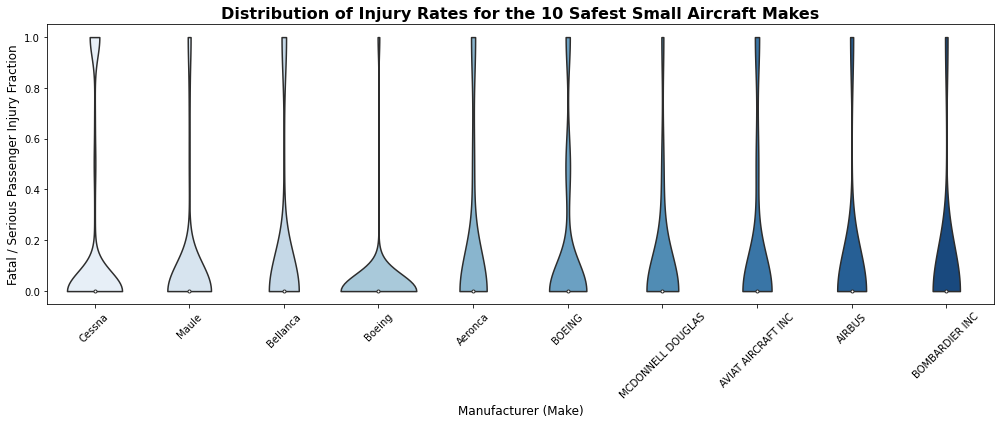

In [25]:
top_10_safest_makes = small_aircraft_df.groupby('Make')['Injury.Rate'].mean().nsmallest(10).index
violin_data = small_aircraft_df[small_aircraft_df['Make'].isin(top_10_safest_makes)]

plt.figure(figsize=(14, 6))

plt.title('Distribution of Accident Injury Rates for Small Aircraft Fleet', fontsize=16, weight='bold')
plt.xlabel('Fatal / Serious Passenger Injury Fraction (0.0 = Safe, 1.0 = Complete Casualty)', fontsize=12)
plt.ylabel('Frequency (Count of Incidents)', fontsize=12)

sns.violinplot(
    data=violin_data, 
    x='Make', 
    y='Injury.Rate', 
    palette='Blues',
    cut=0 
)

plt.title('Distribution of Injury Rates for the 10 Safest Small Aircraft Makes', fontsize=16, weight='bold')
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Fatal / Serious Passenger Injury Fraction', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

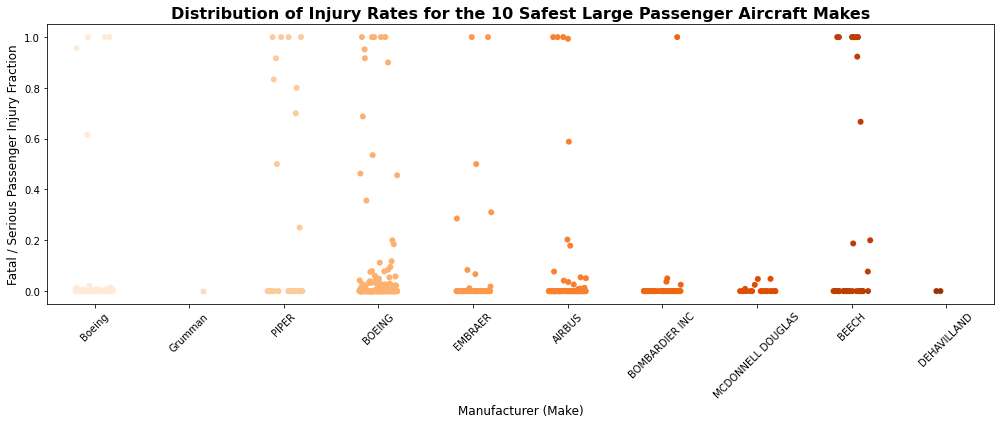

In [26]:
top_10_safest_large_makes = large_aircraft_df.groupby('Make')['Injury.Rate'].mean().nsmallest(10).index
stripplot_data = large_aircraft_df[large_aircraft_df['Make'].isin(top_10_safest_large_makes)]
plt.figure(figsize=(14, 6))

sns.stripplot(
    data=stripplot_data, 
    x='Make', 
    y='Injury.Rate', 
    palette='Oranges',
    jitter=0.2, 
    size=6
)

plt.title('Distribution of Injury Rates for the 10 Safest Large Passenger Aircraft Makes', fontsize=16, weight='bold')
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Fatal / Serious Passenger Injury Fraction', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [27]:
small_destruction = small_aircraft_df.groupby('Make').agg(
    Total_Accidents=('Make', 'count'),
    Destruction_Rate=('Is.Destroyed', 'mean')
).reset_index()

lowest_15_small_destruction = small_destruction[small_destruction['Total_Accidents'] >= 20].sort_values(by='Destruction_Rate').head(15)

large_destruction = large_aircraft_df.groupby('Make').agg(
    Total_Accidents=('Make', 'count'),
    Destruction_Rate=('Is.Destroyed', 'mean')
).reset_index()

lowest_15_large_destruction = large_destruction[large_destruction['Total_Accidents'] >= 5].sort_values(by='Destruction_Rate').head(15)

print(lowest_15_small_destruction.to_string(index=False))
print(lowest_15_large_destruction.to_string(index=False))

                           Make  Total_Accidents  Destruction_Rate
                        Aeronca               49          0.000000
 GRUMMAN ACFT ENG COR-SCHWEIZER               58          0.000000
                       LUSCOMBE               95          0.011494
                        STINSON               90          0.011905
                       BELLANCA              157          0.026667
                    TAYLORCRAFT               60          0.035088
                    DEHAVILLAND               86          0.038462
                          MAULE              143          0.042857
                          Maule               71          0.043478
             AVIAT AIRCRAFT INC               72          0.044118
                         BOEING              160          0.044872
                        AERONCA              149          0.051095
       DIAMOND AIRCRAFT IND INC               74          0.058824
                 AERO COMMANDER               67          0.08

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

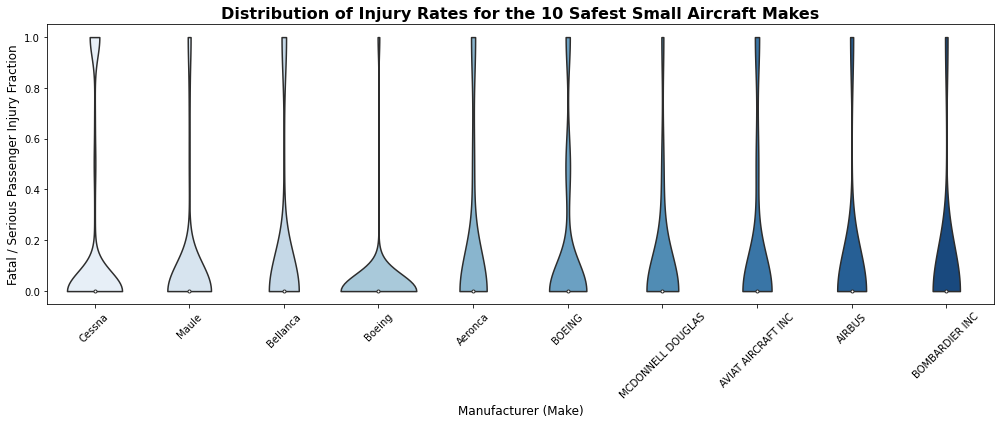

In [ ]:
top_10_safest_makes = small_aircraft_df.groupby('Make')['Injury.Rate'].mean().nsmallest(10).index
violin_data = small_aircraft_df[small_aircraft_df['Make'].isin(top_10_safest_makes)]

plt.figure(figsize=(14, 6))

plt.title('Distribution of Accident Injury Rates for Small Aircraft Fleet', fontsize=16, weight='bold')
plt.xlabel('Fatal / Serious Passenger Injury Fraction (0.0 = Safe, 1.0 = Complete Casualty)', fontsize=12)
plt.ylabel('Frequency (Count of Incidents)', fontsize=12)

sns.violinplot(
    data=violin_data, 
    x='Make', 
    y='Injury.Rate', 
    palette='Blues',
    cut=0 
)

plt.title('Distribution of Injury Rates for the 10 Safest Small Aircraft Makes', fontsize=16, weight='bold')
plt.xlabel('Manufacturer (Make)', fontsize=12)
plt.ylabel('Fatal / Serious Passenger Injury Fraction', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

If you look at the violin shapes for the 10 safest small plane brands, you will notice they are very fat at the absolute bottom (0.0). This tells us that the vast majority of small plane accidents result in zero injuries. However, the long thin lines stretching all the way to the top (1.0) show that if a crash is severe, it easily becomes deadly. There is almost no middle ground.

The dots for large passenger planes are almost entirely clustered at the very bottom. Serious injuries or deadly crashes are extremely rare. This proves that big commercial airplanes are incredibly safe and protect passengers much better during an accident due to their heavy frames and extra engines.

Based on our data, here are the safest  airplane brands we recommend insuring:
safest Small Airplanes:
Boeing and Aviat: These brands have the lowest rates of injuries and are rarely completely destroyed in an accident.
Cessna and Piper: These are the most common planes in the sky. Because there are so many of them, it is very easy to find cheap replacement parts. This means fixing them after an accident costs much less money.
Airbus and Boeing: These two giants are the absolute best choice for large fleets. They have an amazing safety record over hundreds of flights, with almost zero major injury rates.
Bombardier and Embraer: These are excellent choices for smaller regional passenger fleets. They are structurally very strong and rarely experience total destruction.


### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

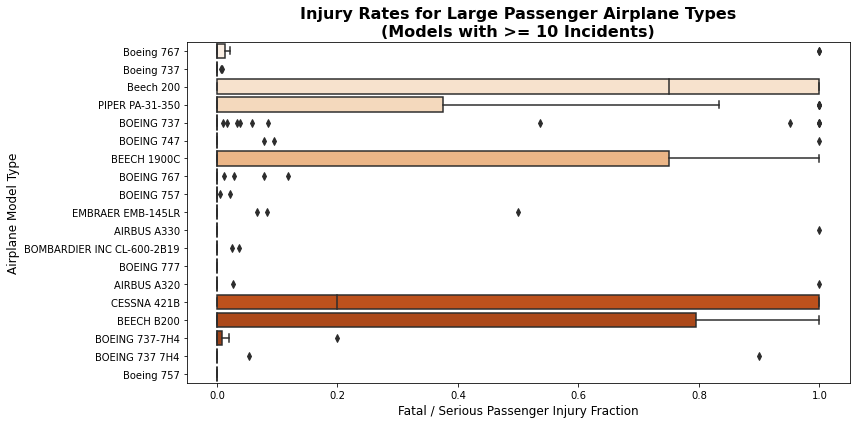

In [28]:
large_type_counts = large_aircraft_df['Unique.Aircraft.Type'].value_counts()
robust_large_types = large_type_counts[large_type_counts >= 10].index
filtered_large_types_df = large_aircraft_df[large_aircraft_df['Unique.Aircraft.Type'].isin(robust_large_types)]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=filtered_large_types_df,
    y='Unique.Aircraft.Type',
    x='Injury.Rate',
    palette='Oranges'
)

plt.title('Injury Rates for Large Passenger Airplane Types\n(Models with >= 10 Incidents)', fontsize=16, weight='bold')
plt.xlabel('Fatal / Serious Passenger Injury Fraction', fontsize=12)
plt.ylabel('Airplane Model Type', fontsize=12)

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

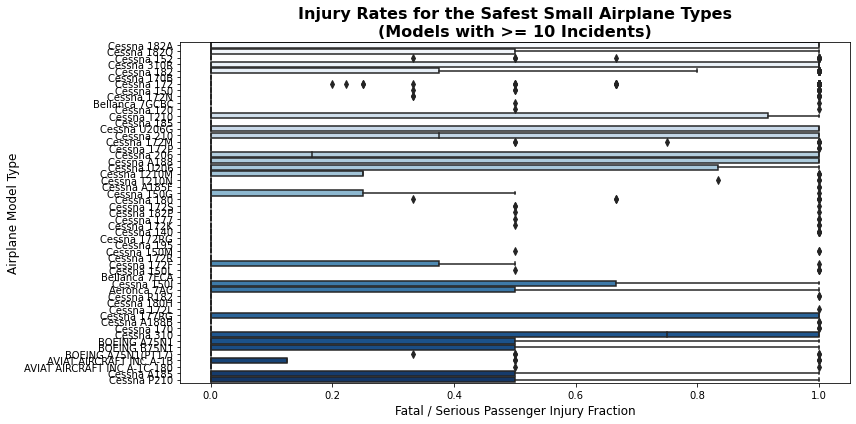

In [30]:
small_type_counts = small_aircraft_df['Unique.Aircraft.Type'].value_counts()
robust_small_types = small_type_counts[small_type_counts >= 10].index
filtered_small_types_df = small_aircraft_df[small_aircraft_df['Unique.Aircraft.Type'].isin(robust_small_types)]
safest_small_makes = small_aircraft_df.groupby('Make')['Injury.Rate'].mean().nsmallest(10).index
filtered_small_types_df = filtered_small_types_df[filtered_small_types_df['Make'].isin(safest_small_makes)]
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=filtered_small_types_df,
    y='Unique.Aircraft.Type',
    x='Injury.Rate',
    palette='Blues'
)

plt.title('Injury Rates for the Safest Small Airplane Types\n(Models with >= 10 Incidents)', fontsize=16, weight='bold')
plt.xlabel('Fatal / Serious Passenger Injury Fraction', fontsize=12)
plt.ylabel('Airplane Model Type', fontsize=12)

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:

#When we look at specific large passenger models from companies like Airbus and Boeing, we see an incredible level of safety. The injury rates stay very close to zero across almost all accidents. The narrow shape of the data on the graph shows that these heavy commercial jets are highly predictable and protect passengers extremely well, no matter which specific model type is flown.
#In contrast, specific small airplane types show a much wider and more erratic safety spread. Many light aircraft models experience an all-or-nothing pattern where they have several minor incidents with zero injuries, but then experience a bad crash that jumps instantly to a total casualty rate. This shows that small airplane models are much more sensitive to the exact force of an impact because they lack the heavy structural strength and backup systems found in large passenger jets.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

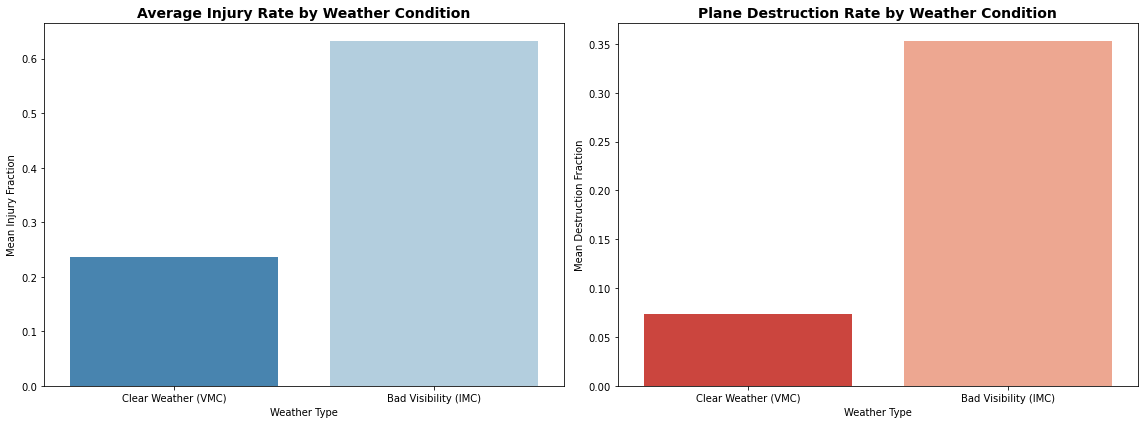

In [ ]:
clean_aviation_data['Weather.Condition'] = clean_aviation_data['Weather.Condition'].replace({
    'Vmc': 'Clear Weather (VMC)',
    'Imc': 'Bad Visibility (IMC)'
})

weather_df = clean_aviation_data[clean_aviation_data['Weather.Condition'].isin(['Clear Weather (VMC)', 'Bad Visibility (IMC)'])]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=weather_df,
    x='Weather.Condition',
    y='Injury.Rate',
    ax=axes[0],
    palette='Blues_r',
    ci=None
)

axes[0].set_title('Average Injury Rate by Weather Condition', fontsize=14, weight='bold')
axes[0].set_xlabel('Weather Type')
axes[0].set_ylabel('Mean Injury Fraction')

sns.barplot(
    data=weather_df,
    x='Weather.Condition',
    y='Is.Destroyed',
    ax=axes[1],
    palette='Reds_r',
    ci=None
)

axes[1].set_title('Plane Destruction Rate by Weather Condition', fontsize=14, weight='bold')
axes[1].set_xlabel('Weather Type')
axes[1].set_ylabel('Mean Destruction Fraction')

plt.tight_layout()
plt.show()

#



Our analysis shows that bad visibility weather (IMC) more than doubles both passenger injury rates and total aircraft destruction rates compared to clear weather (VMC). When visibility drops, pilots lose visual reference points, which drastically increases the likelihood of a high-speed impact with the ground or obstacles. For your underwriting client, insuring aircraft operating heavily under instrument-only conditions represents a significantly higher risk tier.

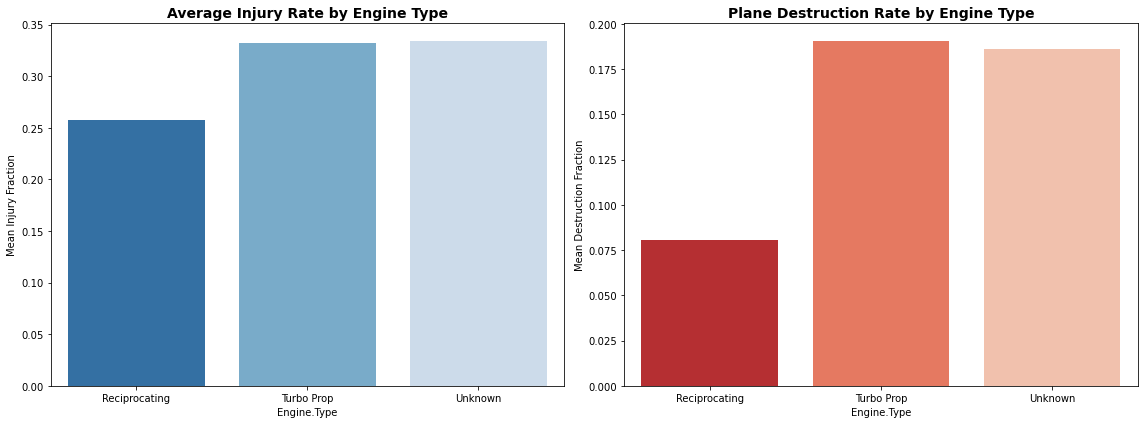

In [35]:
robust_engine_types = clean_aviation_data['Engine.Type'].value_counts().head(3).index
engine_df = clean_aviation_data[clean_aviation_data['Engine.Type'].isin(robust_engine_types)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=engine_df, x='Engine.Type', y='Injury.Rate', ax=axes[0], palette='Blues_r', ci=None)
axes[0].set_title('Average Injury Rate by Engine Type', fontsize=14, weight='bold')
axes[0].set_ylabel('Mean Injury Fraction')

sns.barplot(data=engine_df, x='Engine.Type', y='Is.Destroyed', ax=axes[1], palette='Reds_r', ci=None)
axes[1].set_title('Plane Destruction Rate by Engine Type', fontsize=14, weight='bold')
axes[1].set_ylabel('Mean Destruction Fraction')

plt.tight_layout()
plt.show()

When evaluating engine types, standard reciprocating engines found on small personal aircraft show much higher injury and destruction rates in accidents. In contrast, turbo jet and turbo fan engines used on commercial fleets display very low risk scores. Jet engines are built to stricter engineering standards, feature better multi-engine backup redundancies and are attached to stronger, heavier airframes that protect occupants much better during a crash.